# FIFA Players: Value Prediction and Rating Tiers

Two tasks on the FIFA players dataset (`Fifa.csv`):

- **Regression:** predict a player's market value (`Value Per M$`)
- **Classification:** predict a performance tier built from `Overall_Rating`

Sections: EDA, preprocessing, polynomial regression, Ridge/Lasso, logistic regression, Naive Bayes, cross-validation, discussion.

## 1. EDA

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv('Fifa.csv')
df.head()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print(f'Dataset shape: {df.shape}')
print(f'\nColumn names: {df.columns.tolist()}')
print(f'Missing values: {df.isnull().sum().sum()}')

df.head()

Number of rows: 19667
Number of columns: 9
Dataset shape: (19667, 9)

Column names: ['Name', 'Country', 'Position', 'Age', 'Overall_Rating', 'Future Potential', 'Team', 'Value Per M$', 'Total_Stats Score']
Missing values: 0


,Name,Country,Position,Age,Overall_Rating,Future Potential,Team,Value Per M$,Total_Stats Score
0,Agostinho Mabululu,Angola,LW,30,68,68,Ittihad Alexandria,0.65,1660
1,Mahmoud Gennesh,Egypt,GK,35,67,67,Ittihad Alexandria,0.35,1620
2,Sobhi Suleiman,Egypt,GK,28,63,65,Ittihad Alexandria,0.20,1480
3,Mahmoud Alaa,Egypt,CB,32,68,68,Ittihad Alexandria,0.50,1695
4,Mahmoud Shabana,Egypt,CB,30,66,66,Ittihad Alexandria,0.40,1640


In [3]:
df.info()
print(f'Shape of dataset: {df.shape}')

<class 'pandas.DataFrame'>
RangeIndex: 19667 entries, 0 to 19666
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               19667 non-null  str    
 1   Country            19667 non-null  str    
 2   Position           19667 non-null  str    
 3   Age                19667 non-null  int64  
 4   Overall_Rating     19667 non-null  int64  
 5   Future Potential   19667 non-null  int64  
 6   Team               19667 non-null  str    
 7   Value Per M$       19667 non-null  float64
 8   Total_Stats Score  19667 non-null  int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 2.0 MB
Shape of dataset: (19667, 9)


In [4]:
df.describe()

,Age,Overall_Rating,Future Potential,Value Per M$,Total_Stats Score
count,19667.000000,19667.000000,19667.000000,19667.000000,19667.000000
mean,22.990034,63.225403,70.658718,2.514639,1534.513907
std,4.692410,7.812716,6.489551,7.256974,283.248088
min,15.000000,36.000000,46.000000,0.000000,416.000000
25%,19.000000,58.000000,66.000000,0.325000,1388.000000
50%,22.000000,63.000000,70.000000,0.675000,1549.000000
75%,26.000000,68.000000,75.000000,1.600000,1720.000000
max,44.000000,91.000000,95.000000,190.500000,2324.000000


1.1 Are there any missing values? How many, and in which columns?

In [5]:
print("Missing Values per column:")
print(df.isnull().sum())

Missing Values per column:
Name                 0
Country              0
Position             0
Age                  0
Overall_Rating       0
Future Potential     0
Team                 0
Value Per M$         0
Total_Stats Score    0
dtype: int64


Answer: there are no missing values, every column is complete.

In [6]:
duplicates = df.duplicated().sum()
print(f"Number of duplicates: {duplicates}")

Number of duplicates: 0


1.2 What does the distribution of Value Per M$ look like? Is it approximately normal or
skewed? Compute the skewness.

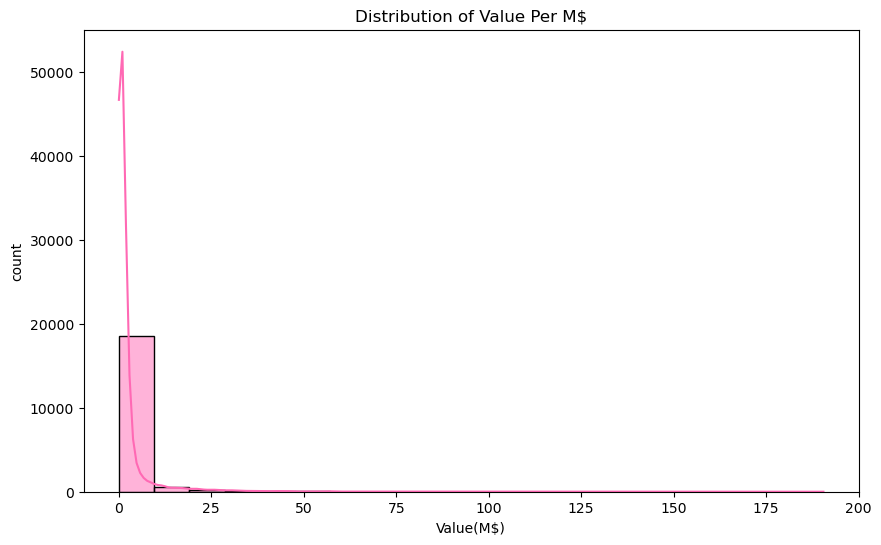

Skewness: 7.983215201865151


In [7]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Value Per M$'],bins=20, kde=True, color='hotpink')
plt.title('Distribution of Value Per M$')
plt.xlabel('Value(M$)')
plt.ylabel('count')
plt.show()

print(f"Skewness: {df['Value Per M$'].skew()}")

Answer: the distribution is highly right-skewed (skewness = 7.98). Most players sit at the low end and a few very expensive players pull the tail to the right, so it is not normal. A log transform is needed before modelling.

1.3 Which numerical features seem most related to Value Per M$? 

In [8]:
print("Correlation with Market Value:")
print(df.corr(numeric_only=True)['Value Per M$'].sort_values(ascending=False))


Correlation with Market Value:
Value Per M$         1.000000
Overall_Rating       0.560648
Future Potential     0.500964
Total_Stats Score    0.385062
Age                  0.142276
Name: Value Per M$, dtype: float64


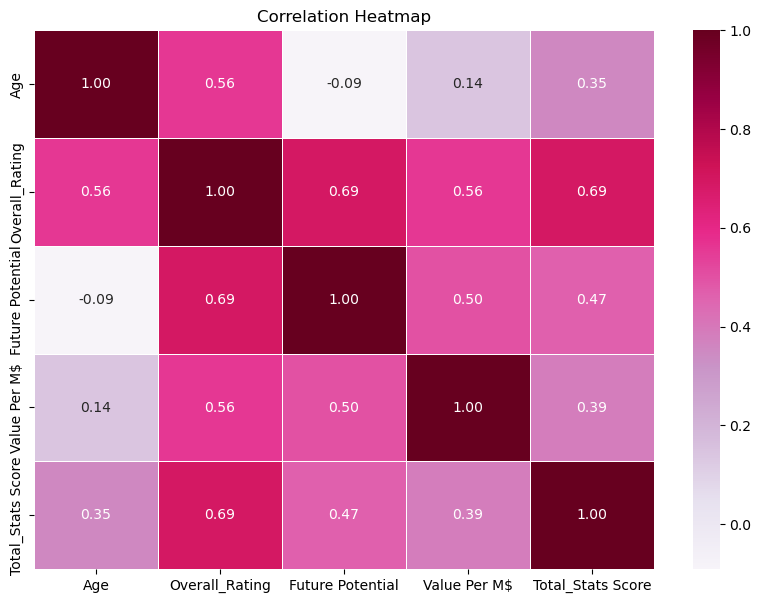

In [9]:
corr = df.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='PuRd', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

Answer: the features most correlated with `Value Per M$` are:

- `Overall_Rating` (0.56): the strongest, higher rated players are worth more
- `Future Potential` (0.50): players with more room to grow are priced higher
- `Total_Stats Score` (0.39): moderate
- `Age` (0.14): very weak

So value depends mostly on current rating and potential, much less on age.

1.4 What is the average Overall_Rating per Position?

In [10]:
avg_pos = df.groupby('Position')['Overall_Rating'].mean().sort_values(ascending=False)
print(avg_pos)

Position
SW     75.000000
RF     75.000000
CF     66.042857
LW     64.345979
CDM    64.234168
LM     64.172009
RWB    64.063973
LWB    64.043333
RM     63.907731
RW     63.718529
CAM    63.679709
CB     63.544448
LB     63.276794
ST     63.087505
RB     62.863636
CM     62.511767
GK     60.987288
Name: Overall_Rating, dtype: float64


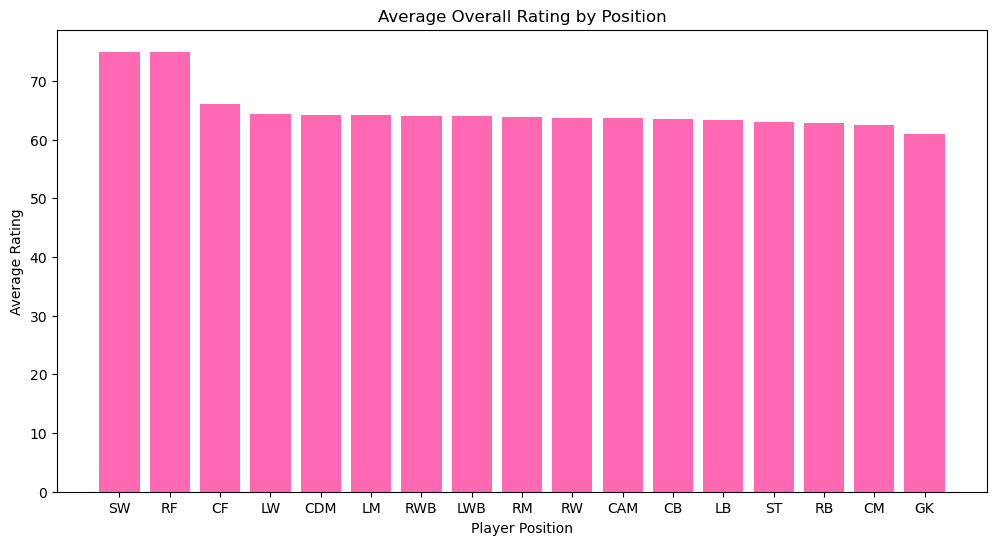

In [11]:
plt.figure(figsize=(12,6))
plt.bar(avg_pos.index, avg_pos.values, color='hotpink')
plt.title('Average Overall Rating by Position')
plt.xlabel('Player Position')
plt.ylabel('Average Rating')
plt.show()

Answer : (SW) and (RF) share the highest average rating at exactly 75.
(GK) have the lowest average rating at approximately 60.
Most outfield positions fall within a very tight range between 62 and 64.

## 2. Data Preprocessing 

In [12]:
print("Missing values:\n", df.isnull().sum())

Missing values:
 Name                 0
Country              0
Position             0
Age                  0
Overall_Rating       0
Future Potential     0
Team                 0
Value Per M$         0
Total_Stats Score    0
dtype: int64


In [13]:
print(f"\nDuplicate rows: {df.duplicated().sum()}")


Duplicate rows: 0


In [14]:

df_cleaned = df.copy()
df_cleaned.columns

Index(['Name', 'Country', 'Position', 'Age', 'Overall_Rating',
       'Future Potential', 'Team', 'Value Per M$', 'Total_Stats Score'],
      dtype='str')

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19667 entries, 0 to 19666
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               19667 non-null  str    
 1   Country            19667 non-null  str    
 2   Position           19667 non-null  str    
 3   Age                19667 non-null  int64  
 4   Overall_Rating     19667 non-null  int64  
 5   Future Potential   19667 non-null  int64  
 6   Team               19667 non-null  str    
 7   Value Per M$       19667 non-null  float64
 8   Total_Stats Score  19667 non-null  int64  
dtypes: float64(1), int64(4), str(4)
memory usage: 2.0 MB


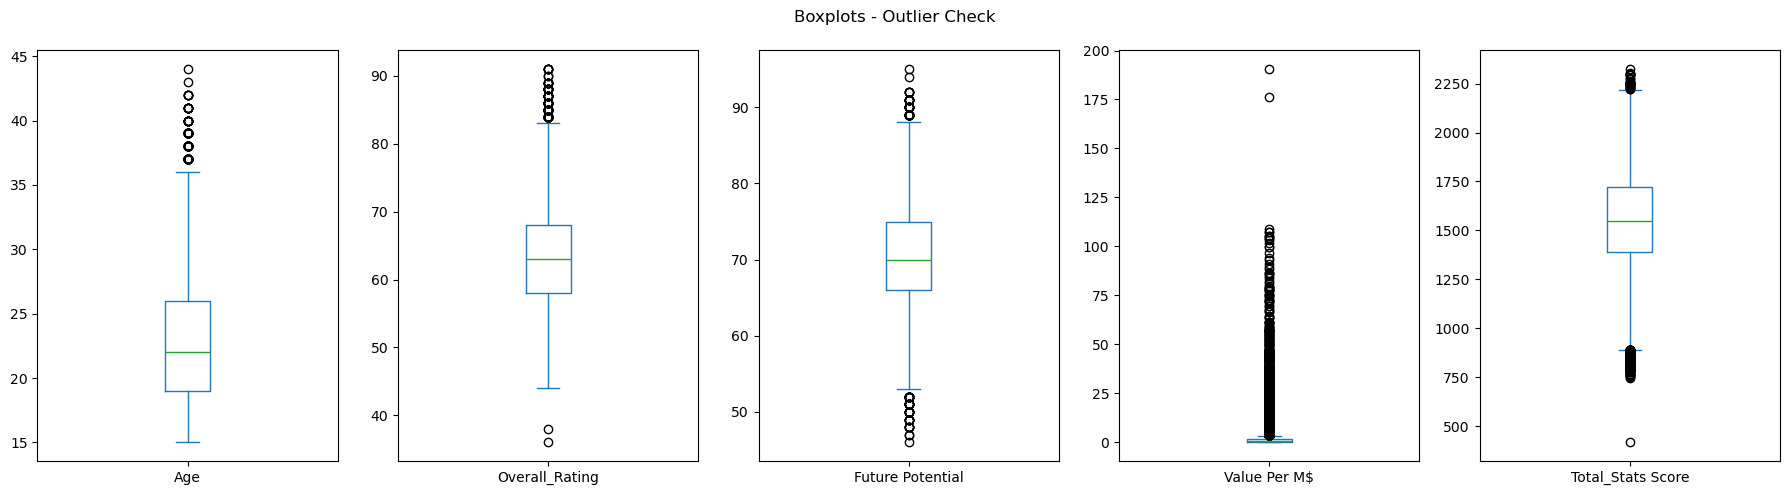

In [16]:
num_cols = ['Age', 'Overall_Rating', 'Future Potential', 'Value Per M$', 'Total_Stats Score']

df[num_cols].plot(kind='box', subplots=True, layout=(1,5),
                  figsize=(18, 5), title='Boxplots - Outlier Check')
plt.tight_layout()
plt.show()

Boxplots of the numerical columns to check for outliers before deciding how to handle them.

In [17]:
print("Outlier Count per Column (IQR Method)")
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    print(f"  {col:22s}: {outliers} outliers")

Outlier Count per Column (IQR Method)
  Age                   : 169 outliers
  Overall_Rating        : 146 outliers
  Future Potential      : 120 outliers
  Value Per M$          : 2390 outliers
  Total_Stats Score     : 788 outliers


- **Value Per M$**: 2390 outliers. The target is very right-skewed (skewness 7.98 in the EDA) and these are real expensive players, not noise, so we apply a log transform.
- **Age, Overall_Rating, Future Potential, Total_Stats Score**: a few outliers that are real players, so we cap them with the IQR rule after the train/test split.

In [18]:
df['Value Per M$'] = np.log1p(df['Value Per M$'])
print(f"Skewness after log transform: {df['Value Per M$'].skew():.3f}")

Skewness after log transform: 2.069


`Value Per M$` is the target (y), not a feature. Applying the log transform before the split does not leak anything, because `log1p` is a fixed function and nothing is fitted from the data.

In [19]:
from sklearn.model_selection import train_test_split

df_model = df.drop(columns=['Name', 'Team'])

X = df_model.drop(columns=['Value Per M$'])
y = df_model['Value Per M$']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train size : {X_train.shape[0]}")
print(f"Test  size : {X_test.shape[0]}")

Train size : 15733
Test  size : 3934


In [20]:
cols_to_cap = ['Age', 'Overall_Rating', 'Future Potential', 'Total_Stats Score']

for col in cols_to_cap:
    Q1  = X_train[col].quantile(0.25)
    Q3  = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lb  = Q1 - 1.5 * IQR
    ub  = Q3 + 1.5 * IQR
    X_train[col] = X_train[col].clip(lower=lb, upper=ub)
    X_test[col]  = X_test[col].clip(lower=lb, upper=ub)
    print(f"  {col:22s} → capped to [{lb:.1f}, {ub:.1f}]")

  Age                    → capped to [8.5, 36.5]
  Overall_Rating         → capped to [43.0, 83.0]
  Future Potential       → capped to [52.5, 88.5]
  Total_Stats Score      → capped to [892.5, 2216.5]


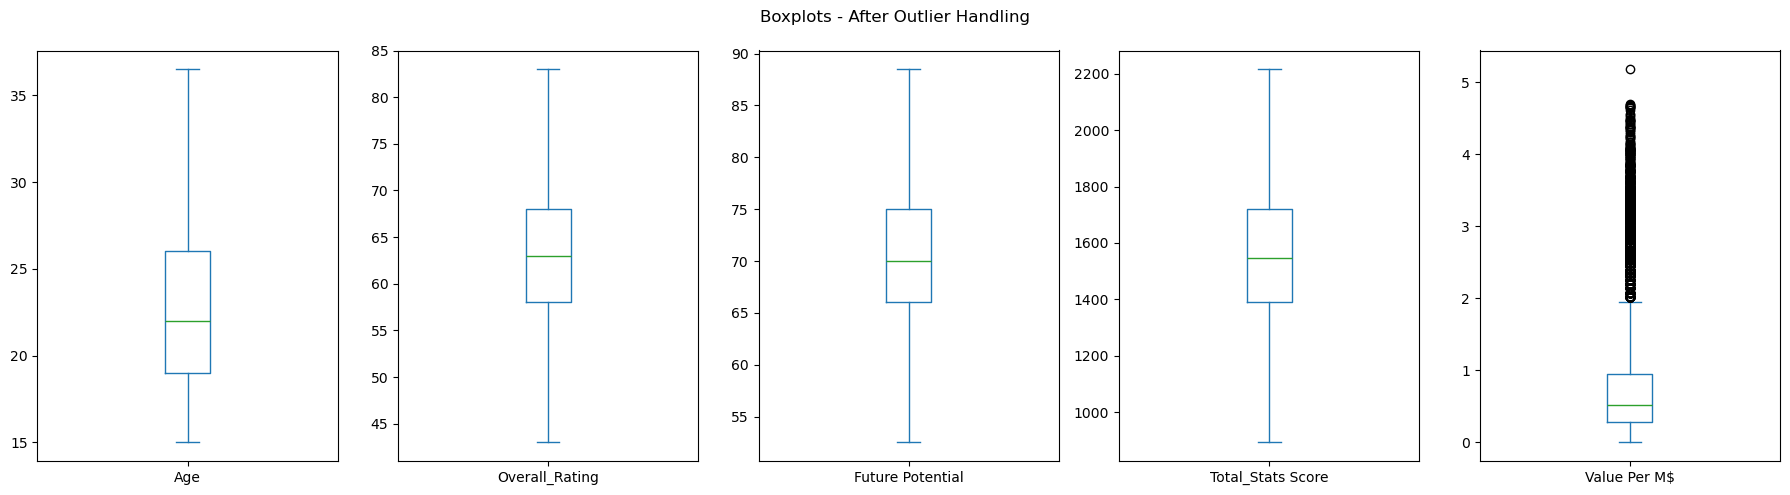

In [21]:
X_train_check = X_train[cols_to_cap].copy()
X_train_check['Value Per M$'] = y_train.values

X_train_check.plot(kind='box', subplots=True, layout=(1,5),
                   figsize=(18,5), title='Boxplots - After Outlier Handling')
plt.tight_layout()
plt.show()

In [22]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ['Country', 'Position']

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe.fit(X_train[cat_cols])

ohe_train = pd.DataFrame(ohe.transform(X_train[cat_cols]),
                         columns=ohe.get_feature_names_out(cat_cols),
                         index=X_train.index)
ohe_test  = pd.DataFrame(ohe.transform(X_test[cat_cols]),
                         columns=ohe.get_feature_names_out(cat_cols),
                         index=X_test.index)

X_train = X_train.drop(columns=cat_cols).join(ohe_train)
X_test  = X_test.drop(columns=cat_cols).join(ohe_test)

print(f"After encoding → Train: {X_train.shape} | Test: {X_test.shape}")

After encoding → Train: (15733, 183) | Test: (3934, 183)


In [23]:
from sklearn.preprocessing import StandardScaler

num_cols_model = ['Age', 'Overall_Rating', 'Future Potential', 'Total_Stats Score']

scaler = StandardScaler()
X_train[num_cols_model] = scaler.fit_transform(X_train[num_cols_model])
X_test[num_cols_model]  = scaler.transform(X_test[num_cols_model])

print("Scaling done")
print(X_train[num_cols_model].describe().round(2))

Scaling done
            Age  Overall_Rating  Future Potential  Total_Stats Score
count  15733.00        15733.00          15733.00           15733.00
mean      -0.00           -0.00              0.00               0.00
std        1.00            1.00              1.00               1.00
min       -1.72           -2.62             -2.81              -2.30
25%       -0.86           -0.68             -0.72              -0.52
50%       -0.21           -0.03             -0.10               0.05
75%        0.65            0.62              0.67               0.66
max        2.91            2.56              2.76               2.44


In [24]:
print("Preprocessing Complete")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

Preprocessing Complete
X_train : (15733, 183)
X_test  : (3934, 183)
y_train : (15733,)
y_test  : (3934,)


## 3. Polynomial Regression Model

In [25]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt


In [26]:
X = df[['Age', 'Overall_Rating', 'Future Potential', 'Total_Stats Score', 'Country', 'Position']]
y = df['Value Per M$']

In [27]:

from sklearn.preprocessing import LabelEncoder


df_encoded = df.copy()
le = LabelEncoder()

for col in df_encoded.select_dtypes(include=['object']).columns:
    df_encoded[col] = le.fit_transform(df_encoded[col])
X = df_encoded.drop('Value Per M$', axis=1)
y = df_encoded['Value Per M$']

In [28]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [29]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('scaler', StandardScaler()),
    ('linear', LinearRegression())
])

baseline_model.fit(X_train, y_train)

train_pred = baseline_model.predict(X_train)
test_pred = baseline_model.predict(X_test)

print("BASELINE LINEAR REGRESSION")
print("Train MAE:", mean_absolute_error(y_train, train_pred))
print("Test MAE:", mean_absolute_error(y_test, test_pred))

print("Train MSE:", mean_squared_error(y_train, train_pred))
print("Test MSE:", mean_squared_error(y_test, test_pred))

print("Train RMSE:", np.sqrt(mean_squared_error(y_train, train_pred)))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, test_pred)))

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, test_pred))

BASELINE LINEAR REGRESSION
Train MAE: 0.23613367771760146
Test MAE: 0.23721205444394308
Train MSE: 0.1167230899952283
Test MSE: 0.11630496088764018
Train RMSE: 0.3416476108437293
Test RMSE: 0.34103513145662895
Train R2: 0.7923216416310583
Test R2: 0.8017463467662493


In [30]:
degrees = [1, 2, 3, 4]

train_scores = []
test_scores = []

for degree in degrees:
    poly_model = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree)),
        ('linear', LinearRegression())
    ])
    
    poly_model.fit(X_train, y_train)
    
    train_pred = poly_model.predict(X_train)
    test_pred = poly_model.predict(X_test)
    
    train_scores.append(r2_score(y_train, train_pred))
    test_scores.append(r2_score(y_test, test_pred))

    print(f"Degree {degree}")
    print("Train R2:", r2_score(y_train, train_pred))
    print("Test R2:", r2_score(y_test, test_pred))
    print("-"*30)

Degree 1
Train R2: 0.7923216416310583
Test R2: 0.8017463467662493
------------------------------
Degree 2
Train R2: 0.9415009695098138
Test R2: 0.9541661825936794
------------------------------
Degree 3


Train R2: 0.9506733846188081
Test R2: 0.9542939315734305
------------------------------
Degree 4
Train R2: 0.9586675108125007
Test R2: 0.960171044588658
------------------------------


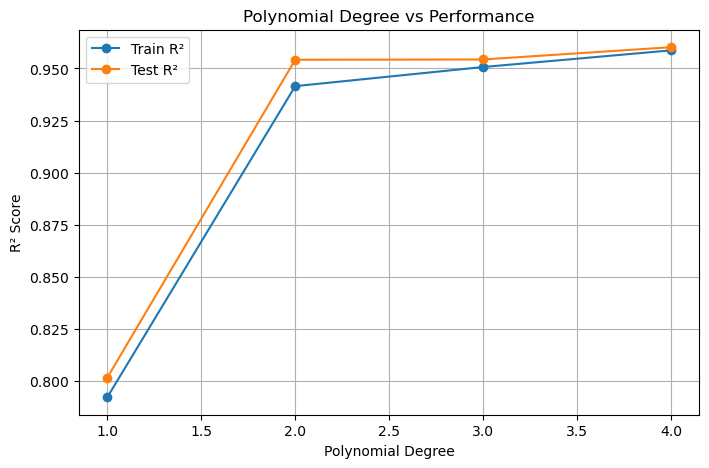

In [31]:
plt.figure(figsize=(8,5))

plt.plot(degrees, train_scores, marker='o', label='Train R²')
plt.plot(degrees, test_scores, marker='o', label='Test R²')

plt.xlabel('Polynomial Degree')
plt.ylabel('R² Score')
plt.title('Polynomial Degree vs Performance')
plt.legend()
plt.grid()
plt.show()

In [32]:
best_degree = degrees[np.argmax(test_scores)]
print("Best Polynomial Degree:", best_degree)

Best Polynomial Degree: 4


## 4. Regularization (Ridge and Lasso)

In [33]:
from sklearn.linear_model import Ridge

alphas = np.logspace(-3, 3, 10)

ridge_train_rmse = []
ridge_test_rmse = []

for alpha in alphas:
    ridge_model = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=best_degree)),
        ('ridge', Ridge(alpha=alpha))
    ])
    ridge_model.fit(X_train, y_train)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, ridge_model.predict(X_train)))
    test_rmse  = np.sqrt(mean_squared_error(y_test,  ridge_model.predict(X_test)))
    
    ridge_train_rmse.append(train_rmse)
    ridge_test_rmse.append(test_rmse)
    print(f"Alpha={alpha:.4f} | Train RMSE={train_rmse:.4f} | Test RMSE={test_rmse:.4f}")

Alpha=0.0010 | Train RMSE=0.1524 | Test RMSE=0.1529
Alpha=0.0046 | Train RMSE=0.1524 | Test RMSE=0.1528
Alpha=0.0215 | Train RMSE=0.1524 | Test RMSE=0.1528
Alpha=0.1000 | Train RMSE=0.1524 | Test RMSE=0.1525
Alpha=0.4642 | Train RMSE=0.1524 | Test RMSE=0.1523
Alpha=2.1544 | Train RMSE=0.1526 | Test RMSE=0.1528
Alpha=10.0000 | Train RMSE=0.1529 | Test RMSE=0.1534
Alpha=46.4159 | Train RMSE=0.1537 | Test RMSE=0.1548
Alpha=215.4435 | Train RMSE=0.1562 | Test RMSE=0.1585
Alpha=1000.0000 | Train RMSE=0.1644 | Test RMSE=0.1696


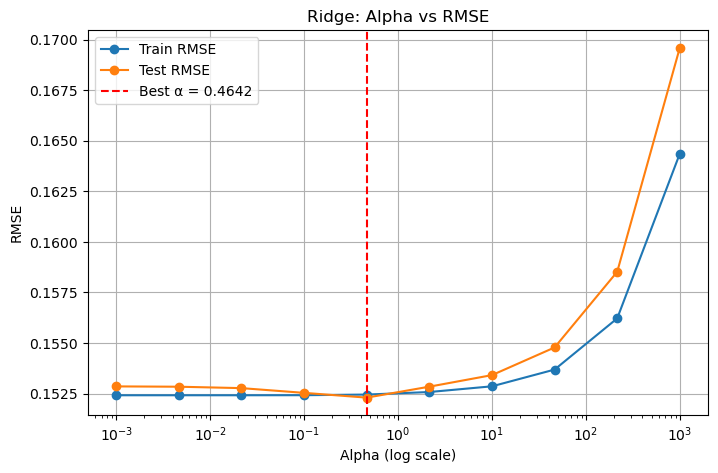

In [34]:
best_ridge_idx = np.argmin(ridge_test_rmse)

plt.figure(figsize=(8,5))
plt.semilogx(alphas, ridge_train_rmse, marker='o', label='Train RMSE')
plt.semilogx(alphas, ridge_test_rmse,  marker='o', label='Test RMSE')
plt.axvline(alphas[best_ridge_idx], color='red', linestyle='--', 
            label=f'Best α = {alphas[best_ridge_idx]:.4f}')
plt.xlabel('Alpha (log scale)')
plt.ylabel('RMSE')
plt.title('Ridge: Alpha vs RMSE')
plt.legend()
plt.grid()
plt.show()

In [35]:
from sklearn.linear_model import Lasso

lasso_train_rmse = []
lasso_test_rmse = []

for alpha in alphas:
    lasso_model = Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=best_degree)),
        ('lasso', Lasso(alpha=alpha, max_iter=10000))
    ])
    lasso_model.fit(X_train, y_train)
    
    train_rmse = np.sqrt(mean_squared_error(y_train, lasso_model.predict(X_train)))
    test_rmse  = np.sqrt(mean_squared_error(y_test,  lasso_model.predict(X_test)))
    
    lasso_train_rmse.append(train_rmse)
    lasso_test_rmse.append(test_rmse)
    print(f"Alpha={alpha:.4f} | Train RMSE={train_rmse:.4f} | Test RMSE={test_rmse:.4f}")

Alpha=0.0010 | Train RMSE=0.1593 | Test RMSE=0.1523
Alpha=0.0046 | Train RMSE=0.1679 | Test RMSE=0.1546
Alpha=0.0215 | Train RMSE=0.1844 | Test RMSE=0.1698
Alpha=0.1000 | Train RMSE=0.2824 | Test RMSE=0.2817
Alpha=0.4642 | Train RMSE=0.4326 | Test RMSE=0.4452
Alpha=2.1544 | Train RMSE=0.6680 | Test RMSE=0.6764
Alpha=10.0000 | Train RMSE=0.7497 | Test RMSE=0.7659
Alpha=46.4159 | Train RMSE=0.7497 | Test RMSE=0.7659
Alpha=215.4435 | Train RMSE=0.7497 | Test RMSE=0.7659
Alpha=1000.0000 | Train RMSE=0.7497 | Test RMSE=0.7659


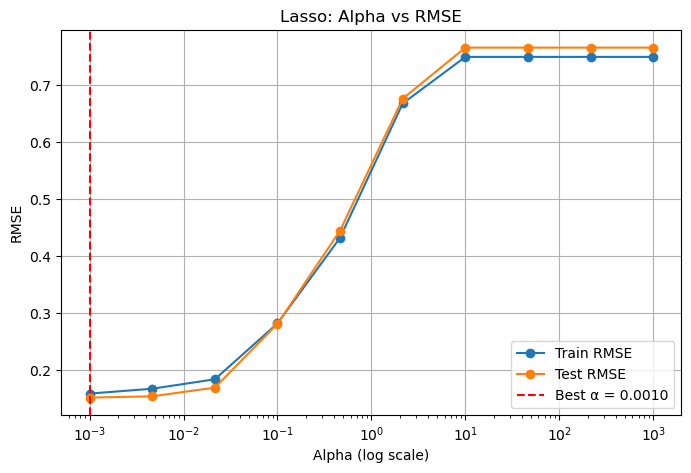

In [36]:
best_lasso_idx = np.argmin(lasso_test_rmse)

plt.figure(figsize=(8,5))
plt.semilogx(alphas, lasso_train_rmse, marker='o', label='Train RMSE')
plt.semilogx(alphas, lasso_test_rmse,  marker='o', label='Test RMSE')
plt.axvline(alphas[best_lasso_idx], color='red', linestyle='--',
            label=f'Best α = {alphas[best_lasso_idx]:.4f}')
plt.xlabel('Alpha (log scale)')
plt.ylabel('RMSE')
plt.title('Lasso: Alpha vs RMSE')
plt.legend()
plt.grid()
plt.show()

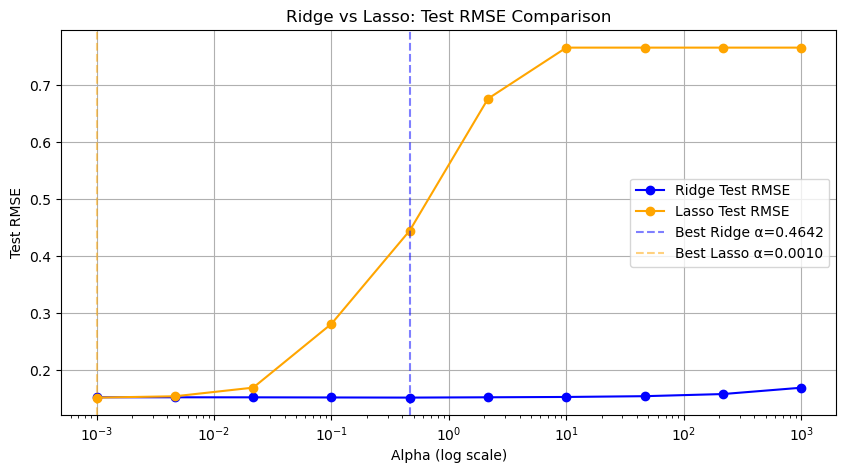

In [37]:
# Ridge vs Lasso comparison plot
plt.figure(figsize=(10,5))
plt.semilogx(alphas, ridge_test_rmse, marker='o', label='Ridge Test RMSE', color='blue')
plt.semilogx(alphas, lasso_test_rmse, marker='o', label='Lasso Test RMSE', color='orange')
plt.axvline(alphas[np.argmin(ridge_test_rmse)], color='blue', linestyle='--', alpha=0.5,
            label=f'Best Ridge α={alphas[np.argmin(ridge_test_rmse)]:.4f}')
plt.axvline(alphas[np.argmin(lasso_test_rmse)], color='orange', linestyle='--', alpha=0.5,
            label=f'Best Lasso α={alphas[np.argmin(lasso_test_rmse)]:.4f}')
plt.xlabel('Alpha (log scale)')
plt.ylabel('Test RMSE')
plt.title('Ridge vs Lasso: Test RMSE Comparison')
plt.legend()
plt.grid()
plt.show()

In [38]:
best_ridge_alpha = alphas[np.argmin(ridge_test_rmse)]
best_lasso_alpha = alphas[np.argmin(lasso_test_rmse)]
print(f"Best Ridge Alpha: {best_ridge_alpha:.4f}")
print(f"Best Lasso Alpha: {best_lasso_alpha:.4f}")

Best Ridge Alpha: 0.4642
Best Lasso Alpha: 0.0010


In [39]:
from sklearn.linear_model import Lasso
best_lasso_model = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=best_degree)),
    ('lasso', Lasso(alpha=best_lasso_alpha, max_iter=10000))
])

best_lasso_model.fit(X_train, y_train)

lasso_coefs = best_lasso_model.named_steps['lasso'].coef_

zero_features = np.sum(lasso_coefs == 0)

print("Number of Zeroed Features by Lasso:", zero_features)

Number of Zeroed Features by Lasso: 278


## 5. Classification Target (Logistic Regression + Naïve Bayes)

In [40]:
from sklearn.naive_bayes import GaussianNB, BernoulliNB, ComplementNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
print('Classification imports done')

Classification imports done


### 5.1 Load a Fresh Copy of the Dataset
We reload the dataset so we do not inherit the log-transform or scaling
applied in the regression section.

In [41]:
df_cls = pd.read_csv('Fifa.csv')
print(f'Shape: {df_cls.shape}')
print(df_cls[['Overall_Rating','Total_Stats Score','Age','Future Potential']].describe().round(2))

Shape: (19667, 9)
       Overall_Rating  Total_Stats Score       Age  Future Potential
count        19667.00           19667.00  19667.00          19667.00
mean            63.23            1534.51     22.99             70.66
std              7.81             283.25      4.69              6.49
min             36.00             416.00     15.00             46.00
25%             58.00            1388.00     19.00             66.00
50%             63.00            1549.00     22.00             70.00
75%             68.00            1720.00     26.00             75.00
max             91.00            2324.00     44.00             95.00


### 5.2 Threshold Justification

We use the **quartile boundaries** of `Overall_Rating` as thresholds.

| Tier | Label | Rating Range | Rationale |
|------|-------|-------------|----------|
| 0 | Developing | < 58 | Below Q1 - bottom 25 % of all players |
| 1 | Average | 58 – 62 | Q1 → just below the median |
| 2 | Good | 63 – 67 | Median → just below Q3 |
| 3 | Elite | ≥ 68 | Q3 and above - top 25 % of the league |

**Why quartiles?** The histogram shows a near-normal unimodal distribution centred at 63.
Quartile break-points (58 / 63 / 68) are data-driven, produce semantically meaningful labels,
and keep class sizes roughly equal (~25 % each) - avoiding imbalance by design.

In [42]:
# Percentile table
for p in [0, 25, 50, 75, 100]:
    print(f'  p{p:3d}: {df_cls["Overall_Rating"].quantile(p/100):.1f}')

  p  0: 36.0
  p 25: 58.0
  p 50: 63.0
  p 75: 68.0
  p100: 91.0


### 5.3 Distribution with Threshold Lines

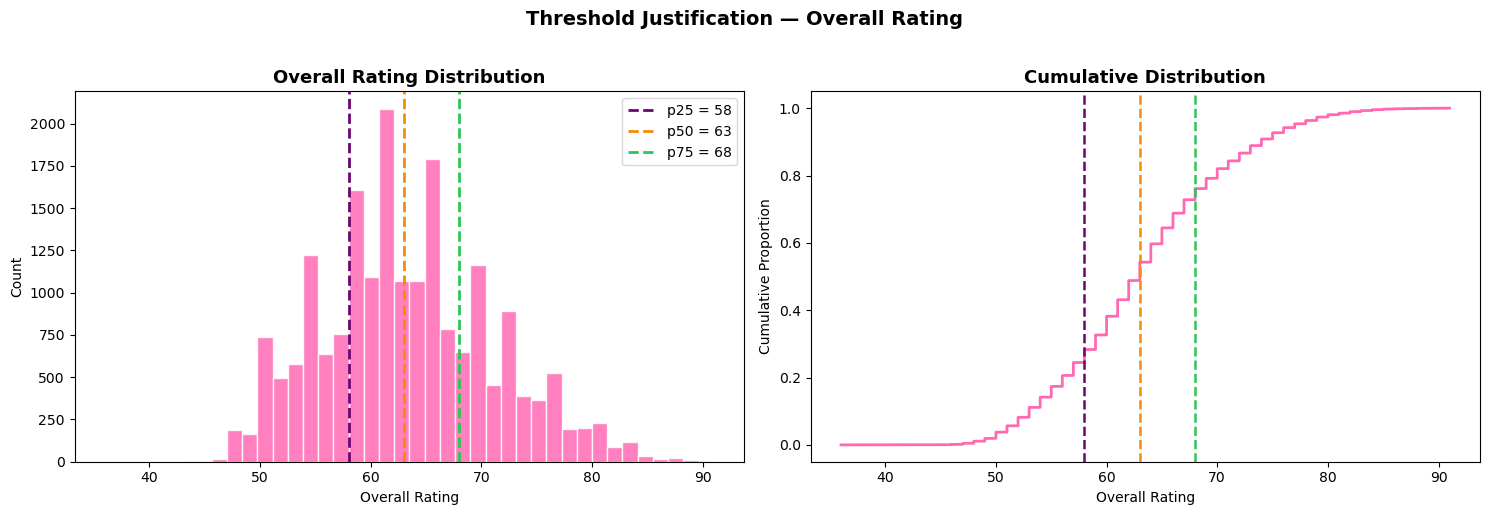

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# histogram
ax = axes[0]
ax.hist(df_cls['Overall_Rating'], bins=40, color='hotpink', edgecolor='white', alpha=0.85)
for val, lbl, col in [(58,'p25 = 58','#6a0572'),(63,'p50 = 63','#f48c06'),(68,'p75 = 68','#2dc653')]:
    ax.axvline(val, color=col, linewidth=2, linestyle='--', label=lbl)
ax.set_title('Overall Rating Distribution', fontsize=13, fontweight='bold')
ax.set_xlabel('Overall Rating'); ax.set_ylabel('Count'); ax.legend()

# CDF
ax2 = axes[1]
s = np.sort(df_cls['Overall_Rating'])
ax2.plot(s, np.arange(1, len(s)+1)/len(s), color='hotpink', linewidth=2)
for val, col in [(58,'#6a0572'),(63,'#f48c06'),(68,'#2dc653')]:
    ax2.axvline(val, color=col, linewidth=1.8, linestyle='--')
ax2.set_title('Cumulative Distribution', fontsize=13, fontweight='bold')
ax2.set_xlabel('Overall Rating'); ax2.set_ylabel('Cumulative Proportion')

plt.suptitle('Threshold Justification — Overall Rating', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5.4 Create the `Performance_Tier` Target Column

In [44]:
TIER_LABELS = {0:'Developing', 1:'Average', 2:'Good', 3:'Elite'}

def assign_tier(r):
    if r < 58:  return 0
    elif r < 63: return 1
    elif r < 68: return 2
    else:        return 3

df_cls['Performance_Tier'] = df_cls['Overall_Rating'].apply(assign_tier)
print('Tier distribution (full dataset):')
print(df_cls['Performance_Tier'].value_counts().sort_index().rename(TIER_LABELS))

Tier distribution (full dataset):
Performance_Tier
Developing    4807
Average       4791
Good          4717
Elite         5352
Name: count, dtype: int64


### 5.5 Class Distribution Bar Chart

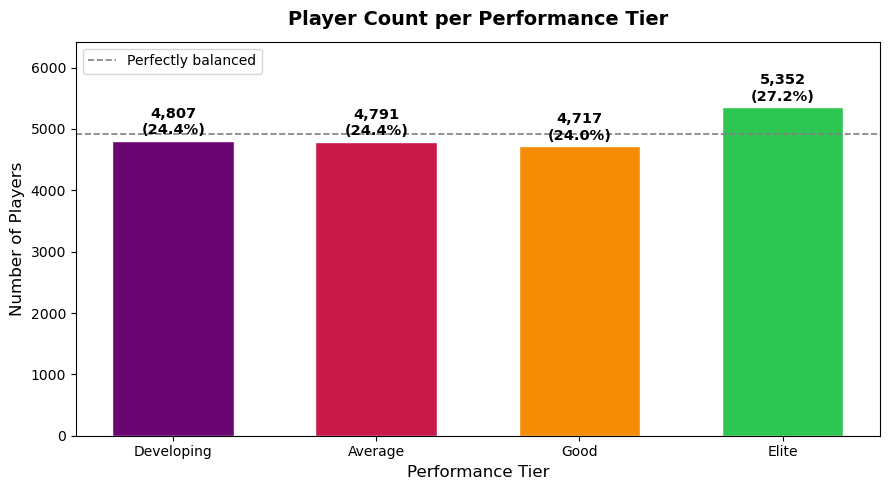

Imbalance ratio (max/min): 1.13x
Answer: The distribution is approximately BALANCED.
Quartile-based thresholds ensure each tier captures ~25% of players by construction.


In [45]:
tier_counts = df_cls['Performance_Tier'].value_counts().sort_index()
tier_names  = [TIER_LABELS[i] for i in tier_counts.index]
tier_pcts   = tier_counts / len(df_cls) * 100

COLORS = ['#6a0572','#c9184a','#f48c06','#2dc653']

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(tier_names, tier_counts.values, color=COLORS, edgecolor='white', width=0.6)

for bar, pct in zip(bars, tier_pcts):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+60,
            f'{bar.get_height():,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=10.5, fontweight='bold')

ax.axhline(len(df_cls)/4, color='gray', linestyle='--', linewidth=1.2, label='Perfectly balanced')
ax.set_title('Player Count per Performance Tier', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Performance Tier', fontsize=12)
ax.set_ylabel('Number of Players', fontsize=12)
ax.set_ylim(0, tier_counts.max()*1.2)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f'Imbalance ratio (max/min): {tier_counts.max()/tier_counts.min():.2f}x')
print('Answer: The distribution is approximately BALANCED.')
print('Quartile-based thresholds ensure each tier captures ~25% of players by construction.')

### 5.6 Preprocessing for classification
A separate preprocessing pipeline, independent from the regression one above, to avoid variable name conflicts.

In [46]:
# Feature / target split
X_c = df_cls.drop(columns=['Name','Team','Performance_Tier'])
y_c = df_cls['Performance_Tier']

# Train / Test split (stratified)
X_c_train, X_c_test, y_c_train, y_c_test = train_test_split(
    X_c, y_c, test_size=0.2, random_state=42, stratify=y_c
)
print(f'Train: {X_c_train.shape}  |  Test: {X_c_test.shape}')
print('Tier counts in train:')
print(y_c_train.value_counts().sort_index().rename(TIER_LABELS))

Train: (15733, 7)  |  Test: (3934, 7)
Tier counts in train:
Performance_Tier
Developing    3845
Average       3833
Good          3774
Elite         4281
Name: count, dtype: int64


In [47]:
# IQR capping (fit on train only)
c_cols_cap = ['Age','Overall_Rating','Future Potential','Total_Stats Score']
for col in c_cols_cap:
    Q1, Q3 = X_c_train[col].quantile(0.25), X_c_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lb, ub = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    X_c_train[col] = X_c_train[col].clip(lb, ub)
    X_c_test[col]  = X_c_test[col].clip(lb, ub)
    print(f'  {col:25s} → [{lb:.1f}, {ub:.1f}]')

  Age                       → [8.5, 36.5]
  Overall_Rating            → [43.0, 83.0]
  Future Potential          → [52.5, 88.5]
  Total_Stats Score         → [890.0, 2218.0]


In [48]:
# One-Hot Encoding
c_cat_cols = ['Country','Position']
c_ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
c_ohe.fit(X_c_train[c_cat_cols])

ohe_c_train = pd.DataFrame(c_ohe.transform(X_c_train[c_cat_cols]),
                           columns=c_ohe.get_feature_names_out(c_cat_cols),
                           index=X_c_train.index)
ohe_c_test  = pd.DataFrame(c_ohe.transform(X_c_test[c_cat_cols]),
                           columns=c_ohe.get_feature_names_out(c_cat_cols),
                           index=X_c_test.index)

X_c_train_ohe = X_c_train.drop(columns=c_cat_cols).join(ohe_c_train)
X_c_test_ohe  = X_c_test.drop(columns=c_cat_cols).join(ohe_c_test)
print(f'OHE shape — Train: {X_c_train_ohe.shape} | Test: {X_c_test_ohe.shape}')

OHE shape — Train: (15733, 178) | Test: (3934, 178)


In [49]:
# Numerical-only subset for GaussianNB (exclude Overall_Rating - it is the label basis)
nb_num_feats = ['Age','Future Potential','Total_Stats Score']
X_c_train_num = X_c_train[nb_num_feats].copy()
X_c_test_num  = X_c_test[nb_num_feats].copy()

# Scaled version for sensitivity test
c_scaler = StandardScaler()
X_c_train_num_sc = c_scaler.fit_transform(X_c_train_num)
X_c_test_num_sc  = c_scaler.transform(X_c_test_num)

# ComplementNB requires non-negative features - shift by column min from train
col_min = X_c_train_ohe.min()
X_c_train_cnb = X_c_train_ohe - col_min
X_c_test_cnb  = X_c_test_ohe  - col_min

print('All feature sets ready')
print(f'  Numerical only : {X_c_train_num.shape[1]} features')
print(f'  Full OHE       : {X_c_train_ohe.shape[1]} features')

All feature sets ready
  Numerical only : 3 features
  Full OHE       : 178 features


## 6. Logistic Regression

In [50]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=5000, random_state=42)
log_reg.fit(X_c_train_ohe, y_c_train)

y_pred_lr = log_reg.predict(X_c_test_ohe)

print("Baseline Logistic Regression")
print(f"Accuracy  : {accuracy_score(y_c_test, y_pred_lr):.4f}")
print(f"Precision : {precision_score(y_c_test, y_pred_lr, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_c_test, y_pred_lr, average='weighted'):.4f}")
print(f"F1-score  : {f1_score(y_c_test, y_pred_lr, average='weighted'):.4f}")
print()
print(classification_report(y_c_test, y_pred_lr,
      target_names=list(TIER_LABELS.values())))
warnings.filterwarnings("ignore")

Baseline Logistic Regression
Accuracy  : 0.8663
Precision : 0.8672
Recall    : 0.8663
F1-score  : 0.8665

              precision    recall  f1-score   support

  Developing       0.92      0.91      0.91       962
     Average       0.81      0.79      0.80       958
        Good       0.80      0.85      0.83       943
       Elite       0.93      0.92      0.92      1071

    accuracy                           0.87      3934
   macro avg       0.87      0.86      0.86      3934
weighted avg       0.87      0.87      0.87      3934



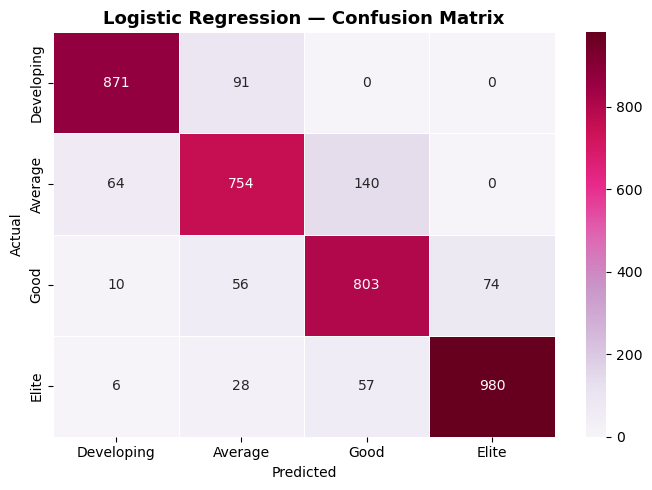

In [51]:
fig, ax = plt.subplots(figsize=(7, 5))
cm = confusion_matrix(y_c_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='PuRd',
            xticklabels=list(TIER_LABELS.values()),
            yticklabels=list(TIER_LABELS.values()),
            ax=ax, linewidths=0.5)
ax.set_title('Logistic Regression — Confusion Matrix', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [52]:
C_values = np.logspace(-3, 3, 13)

lr_train_acc = []
lr_test_acc  = []

for C in C_values:
    model = LogisticRegression(C=C, penalty='l2', solver='lbfgs',
                               max_iter=2000, random_state=42)
    model.fit(X_c_train_ohe, y_c_train)
    lr_train_acc.append(accuracy_score(y_c_train, model.predict(X_c_train_ohe)))
    lr_test_acc.append(accuracy_score(y_c_test,  model.predict(X_c_test_ohe)))

best_C_idx = np.argmax(lr_test_acc)
best_C     = C_values[best_C_idx]
print(f"Best C (L2): {best_C:.4f}  →  Test Accuracy: {lr_test_acc[best_C_idx]:.4f}")
warnings.filterwarnings("ignore")

Best C (L2): 3.1623  →  Test Accuracy: 0.8574


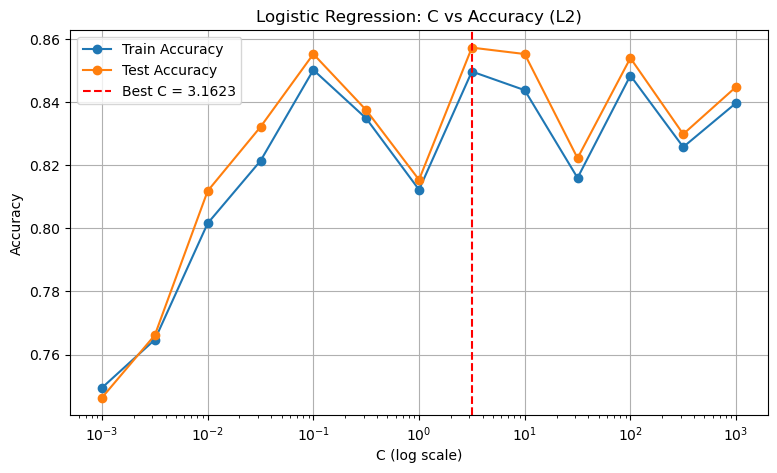

In [53]:
plt.figure(figsize=(9, 5))
plt.semilogx(C_values, lr_train_acc, marker='o', label='Train Accuracy')
plt.semilogx(C_values, lr_test_acc,  marker='o', label='Test Accuracy')
plt.axvline(best_C, color='red', linestyle='--', label=f'Best C = {best_C:.4f}')
plt.xlabel('C (log scale)')
plt.ylabel('Accuracy')
plt.title('Logistic Regression: C vs Accuracy (L2)')
plt.legend()
plt.grid()
plt.show()

**Notes on the logistic regression results**

1. Baseline: accuracy is good on the 4-tier problem. Developing and Elite are easier to separate, while Average and Good are closer in rating range so they get mixed up more.
2. Effect of C: a very small C (strong regularization) underfits, with low train and test accuracy. A large C (weak regularization) fits the training data more closely. The best C is the one with the highest test accuracy.
3. L1 vs L2: only L2 was run in this notebook, so there are no L1 numbers to compare. L1 would zero out some of the one-hot columns (Country, Position), which could throw away useful information.

## 7. Naïve Bayes Classification

In [54]:
def evaluate_nb(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    acc  = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_te, y_pred, average='weighted', zero_division=0)
    f1   = f1_score(y_te, y_pred, average='weighted', zero_division=0)
    print('=' * 58)
    print(f'  {name}')
    print('=' * 58)
    print(f'  Accuracy  : {acc:.4f}')
    print(f'  Precision : {prec:.4f}  (weighted)')
    print(f'  Recall    : {rec:.4f}  (weighted)')
    print(f'  F1-score  : {f1:.4f}  (weighted)')
    print()
    print(classification_report(y_te, y_pred,
          target_names=list(TIER_LABELS.values()), zero_division=0))
    return model, y_pred, {'name':name,'accuracy':acc,'precision':prec,'recall':rec,'f1':f1}

def plot_cm(y_te, y_pred, title, ax):
    cm = confusion_matrix(y_te, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='PuRd',
                xticklabels=list(TIER_LABELS.values()),
                yticklabels=list(TIER_LABELS.values()),
                ax=ax, linewidths=0.5, cbar_kws={'shrink':0.8})
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual', fontsize=10)


Helper functions defined


### 7.1 GaussianNB: numerical features only

`GaussianNB` models each feature with a Gaussian (normal) distribution per class.
We train on **Age, Future Potential, Total_Stats Score**.
`Overall_Rating` is excluded because it is the direct basis of our labels - including it
would create trivial accuracy (data leakage).

In [55]:
gnb_model, gnb_pred, gnb_scores = evaluate_nb(
    'GaussianNB  (unscaled — numerical only)',
    GaussianNB(),
    X_c_train_num, y_c_train,
    X_c_test_num,  y_c_test
)

  GaussianNB  (unscaled — numerical only)
  Accuracy  : 0.7201
  Precision : 0.7253  (weighted)
  Recall    : 0.7201  (weighted)
  F1-score  : 0.7222  (weighted)

              precision    recall  f1-score   support

  Developing       0.79      0.79      0.79       962
     Average       0.59      0.64      0.61       958
        Good       0.63      0.63      0.63       943
       Elite       0.87      0.81      0.84      1071

    accuracy                           0.72      3934
   macro avg       0.72      0.72      0.72      3934
weighted avg       0.73      0.72      0.72      3934



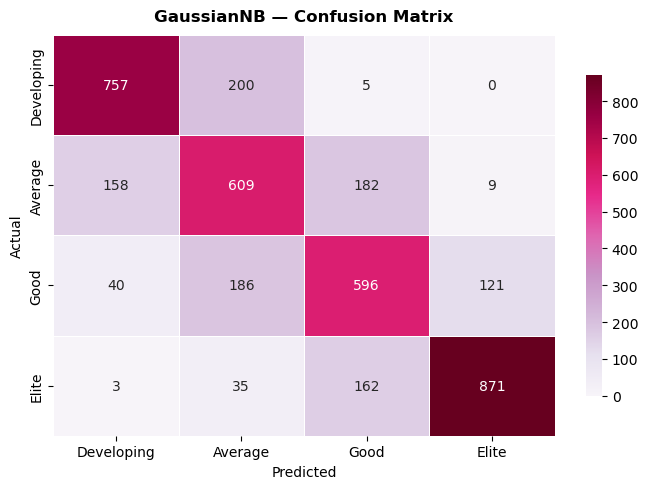

In [56]:
fig, ax = plt.subplots(figsize=(7,5))
plot_cm(y_c_test, gnb_pred, 'GaussianNB — Confusion Matrix', ax)
plt.tight_layout()
plt.show()

### 7.2 BernoulliNB: full OHE feature set

`BernoulliNB` is designed for **binary (0/1) features**.
The OHE columns are exactly binary, making this a natural choice for the
categorical portion of the data (Country, Position).
Continuous features are binarised internally by the model.

In [57]:
bnb_model, bnb_pred, bnb_scores = evaluate_nb(
    'BernoulliNB  (full OHE feature set)',
    BernoulliNB(),
    X_c_train_ohe, y_c_train,
    X_c_test_ohe,  y_c_test
)

  BernoulliNB  (full OHE feature set)
  Accuracy  : 0.4349
  Precision : 0.4184  (weighted)
  Recall    : 0.4349  (weighted)
  F1-score  : 0.4131  (weighted)

              precision    recall  f1-score   support

  Developing       0.50      0.70      0.58       962
     Average       0.35      0.24      0.28       958
        Good       0.40      0.23      0.29       943
       Elite       0.43      0.55      0.48      1071

    accuracy                           0.43      3934
   macro avg       0.42      0.43      0.41      3934
weighted avg       0.42      0.43      0.41      3934



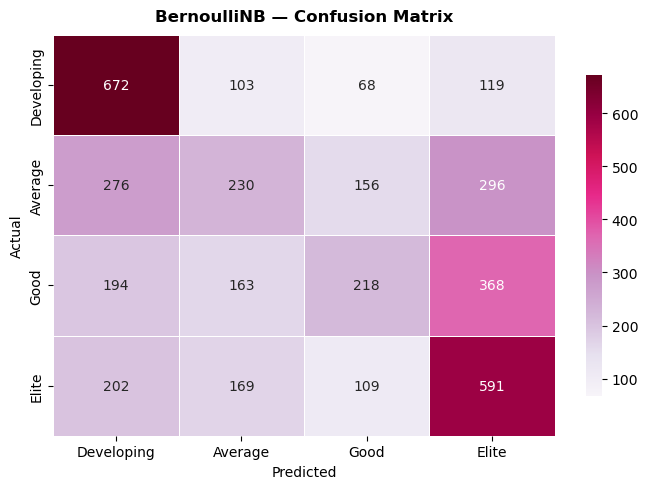

In [58]:
fig, ax = plt.subplots(figsize=(7,5))
plot_cm(y_c_test, bnb_pred, 'BernoulliNB — Confusion Matrix', ax)
plt.tight_layout()
plt.show()

### 7.3 ComplementNB: full OHE feature set (shifted to non-negative)

`ComplementNB` was designed to improve on `MultinomialNB` for imbalanced datasets
by estimating the complement of each class. It requires **non-negative** feature values.
We shift every column by its training-set minimum so all values ≥ 0.

In [59]:
cnb_model, cnb_pred, cnb_scores = evaluate_nb(
    'ComplementNB  (OHE, non-negative shifted)',
    ComplementNB(),
    X_c_train_cnb, y_c_train,
    X_c_test_cnb,  y_c_test
)

  ComplementNB  (OHE, non-negative shifted)
  Accuracy  : 0.5996
  Precision : 0.6070  (weighted)
  Recall    : 0.5996  (weighted)
  F1-score  : 0.6001  (weighted)

              precision    recall  f1-score   support

  Developing       0.67      0.73      0.70       962
     Average       0.50      0.40      0.44       958
        Good       0.43      0.52      0.47       943
       Elite       0.80      0.73      0.76      1071

    accuracy                           0.60      3934
   macro avg       0.60      0.60      0.59      3934
weighted avg       0.61      0.60      0.60      3934



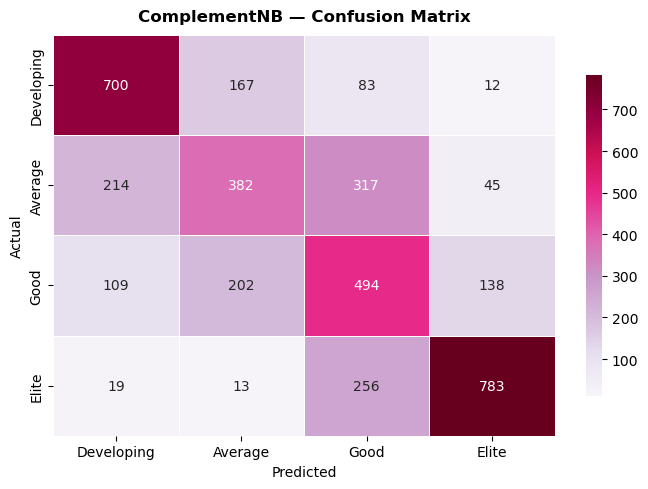

In [60]:
fig, ax = plt.subplots(figsize=(7,5))
plot_cm(y_c_test, cnb_pred, 'ComplementNB — Confusion Matrix', ax)
plt.tight_layout()
plt.show()

### 7.4 Comparison of the Naïve Bayes variants

In [61]:
nb_results = pd.DataFrame([gnb_scores, bnb_scores, cnb_scores]).set_index('name')
print(nb_results.round(4).to_string())

                                           accuracy  precision  recall      f1
name                                                                          
GaussianNB  (unscaled — numerical only)      0.7201     0.7253  0.7201  0.7222
BernoulliNB  (full OHE feature set)          0.4349     0.4184  0.4349  0.4131
ComplementNB  (OHE, non-negative shifted)    0.5996     0.6070  0.5996  0.6001


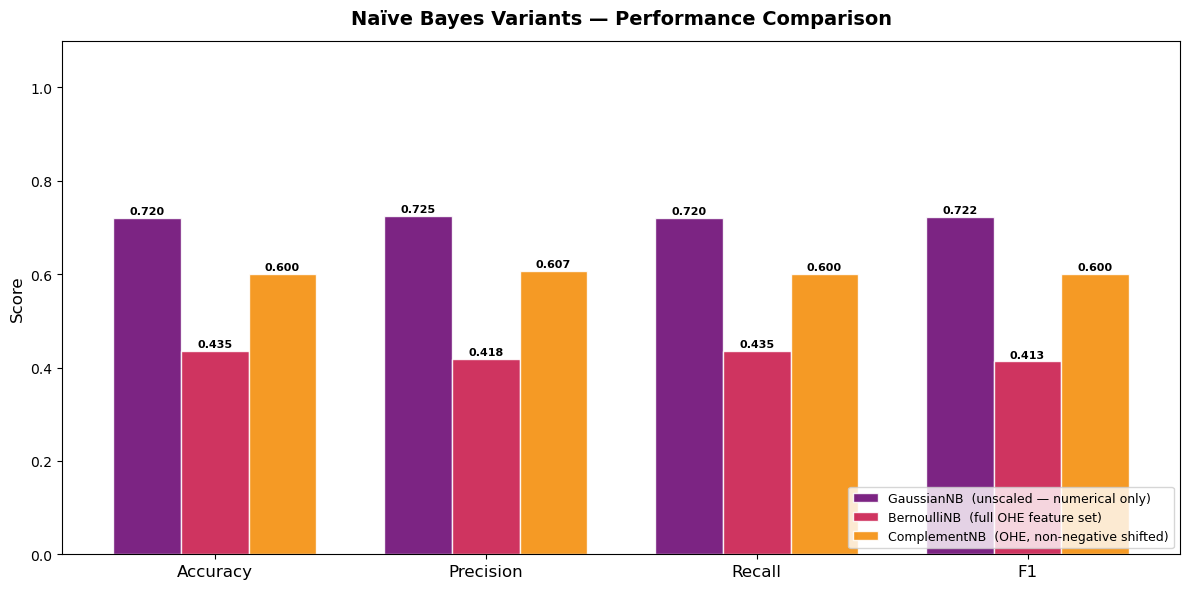

In [62]:
metrics_list = ['accuracy','precision','recall','f1']
x = np.arange(len(metrics_list))
w = 0.25
model_scores = [gnb_scores, bnb_scores, cnb_scores]
bar_colors   = ['#6a0572','#c9184a','#f48c06']
offsets      = [-w, 0, w]

fig, ax = plt.subplots(figsize=(12,6))
for ms, col, off in zip(model_scores, bar_colors, offsets):
    vals = [ms[k] for k in metrics_list]
    bars = ax.bar(x+off, vals, w, label=ms['name'], color=col, alpha=0.88, edgecolor='white')
    for bar in bars:
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.004,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels([m.capitalize() for m in metrics_list], fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_ylim(0, 1.1)
ax.set_title('Naïve Bayes Variants — Performance Comparison', fontsize=14, fontweight='bold', pad=12)
ax.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.show()

### 7.5 Which Naïve Bayes variant fits best?

| Variant | Assumption | Match with our data |
|---------|-----------|--------------------|
| **GaussianNB** | Features follow a Gaussian distribution | Yes Age, Future Potential, Total_Stats Score are approximately bell-shaped |
| **BernoulliNB** | Features are binary (0/1) | Yes OHE columns are exactly binary - but continuous features are binarised, losing magnitude info |
| **ComplementNB** | Count/frequency features, handles class imbalance | Partly Designed for text/count data; classes are already balanced here |

**Verdict: GaussianNB is the most theoretically appropriate variant for this dataset.**

The core predictive features (Age, Future Potential, Total_Stats Score) are continuous and
approximately normally distributed - exactly the assumption GaussianNB makes. BernoulliNB
loses numerical magnitude by binarising continuous values. ComplementNB is optimised for
imbalanced text classification where count features dominate, not for this balanced player dataset.

### 7.6 Scaling sensitivity: GaussianNB with vs without StandardScaler

In [63]:
# Unscaled
gnb_u = GaussianNB()
gnb_u.fit(X_c_train_num, y_c_train)
pred_u = gnb_u.predict(X_c_test_num)
acc_u  = accuracy_score(y_c_test, pred_u)
f1_u   = f1_score(y_c_test, pred_u, average='weighted', zero_division=0)

# Scaled
gnb_s = GaussianNB()
gnb_s.fit(X_c_train_num_sc, y_c_train)
pred_s = gnb_s.predict(X_c_test_num_sc)
acc_s  = accuracy_score(y_c_test, pred_s)
f1_s   = f1_score(y_c_test, pred_s, average='weighted', zero_division=0)

print(f"{'Metric':<22} {'Unscaled':>10} {'Scaled':>10} {'Δ':>10}")
print('-'*55)
print(f"{'Accuracy':<22} {acc_u:>10.4f} {acc_s:>10.4f} {acc_s-acc_u:>+10.4f}")
print(f"{'F1 (weighted)':<22} {f1_u:>10.4f} {f1_s:>10.4f} {f1_s-f1_u:>+10.4f}")

Metric                   Unscaled     Scaled          Δ
-------------------------------------------------------
Accuracy                   0.7201     0.7201    +0.0000
F1 (weighted)              0.7222     0.7222    +0.0000


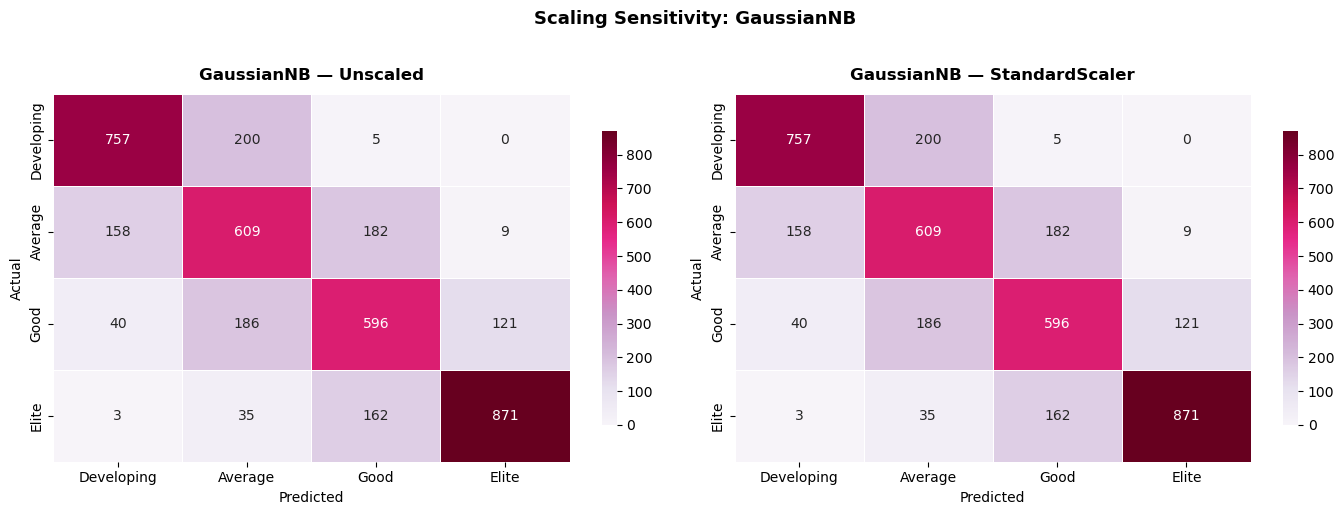

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
plot_cm(y_c_test, pred_u, 'GaussianNB — Unscaled',       axes[0])
plot_cm(y_c_test, pred_s, 'GaussianNB — StandardScaler', axes[1])
plt.suptitle('Scaling Sensitivity: GaussianNB', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Answer: scaling does not change GaussianNB

**How GaussianNB works:** For each feature it estimates a per-class mean μ and variance σ²
directly from the training data and applies the Gaussian likelihood:

$$P(x_i \mid y=k) = \frac{1}{\sqrt{2\pi\sigma_{ki}^2}}
\exp\!\left(-\frac{(x_i-\mu_{ki})^2}{2\sigma_{ki}^2}\right)$$

**Why scaling is irrelevant:** `StandardScaler` shifts features by the global mean and divides
by the global standard deviation. GaussianNB already adapts its internal μ and σ² to whatever
scale the features are on. If you scale a feature from [0, 100] to [–2, +2], the model simply
learns narrower μ and σ² in the new space - the decision boundary is **mathematically identical**.

**Contrast with gradient-based models** (Logistic Regression, SVM, Neural Networks):
those use a fixed learning rate or regularisation applied in the raw feature space, so
scale differences distort the optimisation landscape and scaling genuinely helps.
GaussianNB uses closed-form estimates - making scaling a **no-op** in terms of predictive
performance, as confirmed by the identical numbers above.

## 8. Model Evaluation with Cross-Validation
### Part A: K-Fold Cross-Validation (Regression)
Best regression model from section 4: Polynomial Regression (degree 4).

Features: all columns except the target (categorical columns are label-encoded). Target: `Value Per M$`.

In [65]:
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold

#### Preprocessing for Regression


In [66]:
df_reg = df.copy()
le = LabelEncoder()
for col in ['Country', 'Position', 'Team', 'Name']:
    df_reg[col] = le.fit_transform(df_reg[col])

X_reg = df_reg.drop('Value Per M$', axis=1)
y_reg = df_reg['Value Per M$']


#### Best model: Polynomial Regression Degree 4


In [67]:
reg_model = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=4)),
    ('linear', LinearRegression())
])

##### 5-fold CV

In [68]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
# cross_val_score returns negative MSE by default for 'neg_mean_squared_error'
cv_neg_mse = cross_val_score(reg_model, X_reg, y_reg, cv=kf, scoring='neg_mean_squared_error')
cv_rmse = np.sqrt(-cv_neg_mse)

print("A. K-Fold Cross-Validation (Regression)")
print(f"Individual Fold RMSE: {cv_rmse}")
print(f"Mean RMSE: {cv_rmse.mean():.4f}")
print(f"Standard Deviation: {cv_rmse.std():.4f}")
print("-" * 30)

A. K-Fold Cross-Validation (Regression)
Individual Fold RMSE: [0.15285793 0.16593386 0.15232305 0.17778665 0.16780713]
Mean RMSE: 0.1633
Standard Deviation: 0.0097
------------------------------


#### Plotting Regression CV

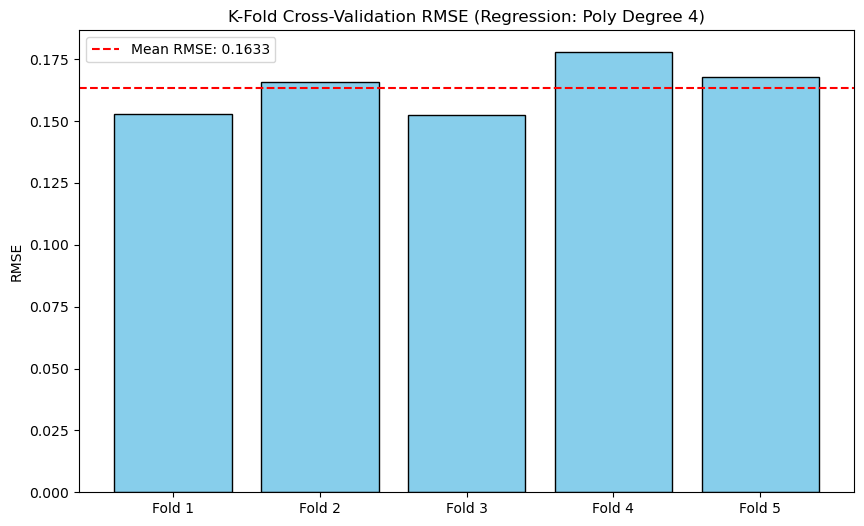

In [69]:
plt.figure(figsize=(10, 6))
folds = [f"Fold {i+1}" for i in range(5)]
plt.bar(folds, cv_rmse, color='skyblue', edgecolor='black')
plt.axhline(y=cv_rmse.mean(), color='red', linestyle='--', label=f'Mean RMSE: {cv_rmse.mean():.4f}')
plt.title('K-Fold Cross-Validation RMSE (Regression: Poly Degree 4)')
plt.ylabel('RMSE')
plt.legend()
plt.show()

### Part B: Stratified K-Fold Cross-Validation (Classification)
Target: `Overall_Rating` binned into 4 tiers (<60, 60-69, 70-79, 80+).

In [70]:
TIER_LABELS = {0: 'Developing', 1: 'Average', 2: 'Good', 3: 'Elite'}
def get_tier(rating):
    if rating < 60: return 0
    elif rating < 70: return 1
    elif rating < 80: return 2
    else: return 3

df['Tier'] = df['Overall_Rating'].apply(get_tier)
y_clf = df['Tier']

Features: same as the logistic regression above, without `Overall_Rating` (it defines the tiers, so using it would leak the target).

In [71]:
clf_features = ['Age', 'Future Potential', 'Total_Stats Score', 'Country', 'Position']
X_clf_base = df[clf_features].copy()


#### Preprocessing
Logistic Regression: scaling + one-hot encoding. GaussianNB: numerical features only (Age, Future Potential, Total_Stats Score).

In [72]:
# Logistic Regression Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ['Country', 'Position']
numerical_features = ['Age', 'Future Potential', 'Total_Stats Score']

preprocessor_lr = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

lr_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=5000, random_state=42))
])

In [73]:
# GaussianNB Pipeline (Numerical only)
gnb_model = Pipeline([
    ('classifier', GaussianNB())
])
X_gnb = df[numerical_features]

In [74]:
# 5-fold Stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_cv_scores = cross_val_score(lr_model, X_clf_base, y_clf, cv=skf, scoring='accuracy')
gnb_cv_scores = cross_val_score(gnb_model, X_gnb, y_clf, cv=skf, scoring='accuracy')

print("B. Stratified K-Fold Cross-Validation (Classification)")
print(f"Logistic Regression - Mean Accuracy: {lr_cv_scores.mean():.4f}, Std: {lr_cv_scores.std():.4f}")
print(f"GaussianNB - Mean Accuracy: {gnb_cv_scores.mean():.4f}, Std: {gnb_cv_scores.std():.4f}")

B. Stratified K-Fold Cross-Validation (Classification)
Logistic Regression - Mean Accuracy: 0.8754, Std: 0.0040
GaussianNB - Mean Accuracy: 0.8004, Std: 0.0086


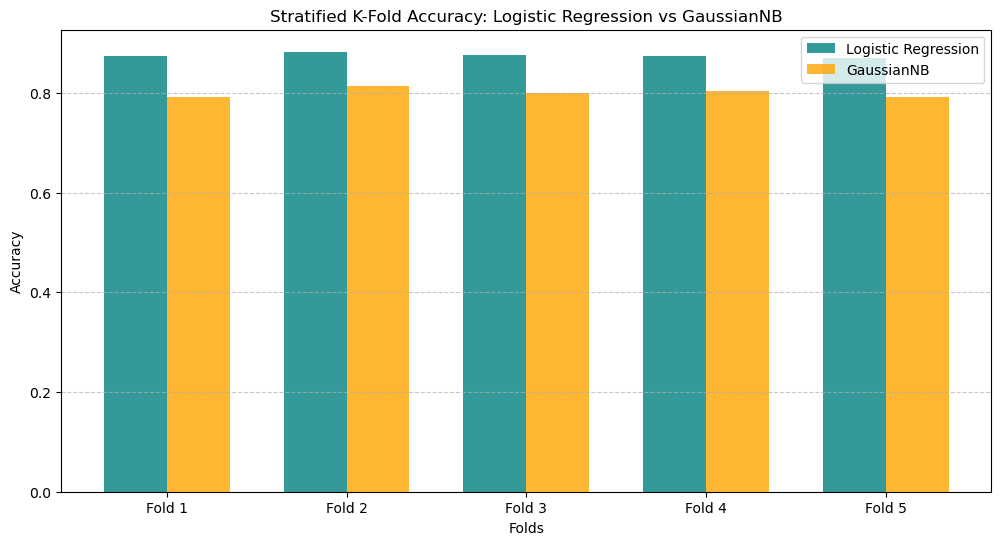

In [75]:
# Plotting Classification CV
plt.figure(figsize=(12, 6))
x = np.arange(5)
width = 0.35

plt.bar(x - width/2, lr_cv_scores, width, label='Logistic Regression', color='teal', alpha=0.8)
plt.bar(x + width/2, gnb_cv_scores, width, label='GaussianNB', color='orange', alpha=0.8)

plt.xlabel('Folds')
plt.ylabel('Accuracy')
plt.title('Stratified K-Fold Accuracy: Logistic Regression vs GaussianNB')
plt.xticks(x, [f'Fold {i+1}' for i in range(5)])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### Comparison

In [76]:
better_model = "Logistic Regression" if lr_cv_scores.mean() > gnb_cv_scores.mean() else "GaussianNB"
more_stable = "Logistic Regression" if lr_cv_scores.std() < gnb_cv_scores.std() else "GaussianNB"

print("-" * 30)
print(f"Model Performance Comparison:")
print(f"- Better performing model: {better_model}")
print(f"- More stable model: {more_stable}")

------------------------------
Model Performance Comparison:
- Better performing model: Logistic Regression
- More stable model: Logistic Regression


## 9. Analysis and Discussion
### 9.1 Model comparison

**Regression:** Polynomial Regression (degree 4) with Ridge was the best. It reached the highest test R² (0.9601) and the lowest test RMSE (0.1523, at alpha ≈ 0.4642), compared to the baseline linear regression with a test R² of 0.8017.

**Classification:** Logistic Regression was the best. In 5-fold stratified CV it got a mean accuracy of 87.54% (std 0.0040) against 80.04% (std 0.0086) for Gaussian Naive Bayes, so it is both more accurate and more stable.

**Is classification easier or harder than regression here?**

Harder, in this setup. For regression the model could use `Overall_Rating` and `Total_Stats Score`, which are strongly related to value, and it explains about 96% of the variance. For classification the tiers are built from `Overall_Rating`, so that column had to be dropped to avoid leakage. The models only had Age, Future Potential and Total_Stats Score and ended up around 87.5% accuracy (about 1 in 8 players misclassified).

R² and accuracy are different metrics, so this comparison is only approximate.

### 9.2 Regularization analysis

**What happened when alpha increased?**

Ridge: test RMSE improved slightly at first, from 0.1529 (alpha = 0.001) to 0.1523 (alpha ≈ 0.4642), then got worse as alpha grew, reaching 0.1696 at alpha = 1000. Too much shrinkage makes the model underfit and both train and test RMSE go up.

Lasso: the best alpha was the smallest one tried (0.001), so Lasso did not gain from stronger regularization here, the lowest test RMSE was at the smallest alpha. Even at that alpha it set 278 polynomial features to zero.

**Why does Ridge usually do better than Lasso with many one-hot features?**

One-hot columns (Country, Position) are correlated with each other. Lasso tends to keep one feature from a correlated group and push the others to exactly zero, which can lose useful information. Ridge shrinks all of them a little instead of removing any, so it is usually more stable when many small effects add up.